<a href="https://colab.research.google.com/github/muhammad-siddique-research/muhammad-siddique-research/blob/main/Algorithm_Evaluation_Extravaganza_UCI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Algorithm Evaluation Extravaganza
## Predicting online purchases using a real UCI dataset

**Practical Google Colab assignment | Binary classification**

**Research question:** How well can Decision Tree, K-Nearest Neighbors (KNN), and Gaussian Naive Bayes predict whether an online shopping session results in a purchase?

**Learning objectives:** (1) obtain a real dataset, (2) critically inspect data quality, (3) implement leakage-safe preprocessing, (4) compare at least three algorithms with stratified cross-validation, (5) evaluate a held-out test set, (6) explain strengths, weaknesses and operational implications.

**Dataset:** Sakar & Kastro (2018), *Online Shoppers Purchasing Intention Dataset*, UCI ML Repository, https://doi.org/10.24432/C5F88Q.

**Academic integrity note:** This notebook produces *your own* results when you execute it. Replace every interpretation prompt with findings from your run; do not report illustrative figures as empirical results.

> **Research portfolio note:** This notebook accompanies the GitHub repository `ecommerce-purchase-prediction-ml`. Metrics are **not** reported until the cells execute on the real UCI dataset. See the README for reproducibility and dataset availability constraints.


### Step 1 — Set up Google Colab

1. Open https://colab.research.google.com/.
2. Upload this `.ipynb` using **File → Upload notebook** (or choose the upload tab).
3. Choose **Runtime → Run all**, or execute each cell in order with **Shift+Enter**.
4. Read every Markdown explanation; answer reflection prompts in your own words.

The first cell installs the official UCI dataset-fetching package. Internet access is needed in Colab for the initial download.

In [ ]:
%pip -q install ucimlrepo

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay, classification_report
)
from sklearn.base import clone

RANDOM_STATE = 42
print('pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)

pandas: 2.2.3 | scikit-learn: 1.6.1


### Step 2 — Retrieve and inspect the genuine dataset

UCI reports 12,330 shopping sessions, 17 predictors, and a binary target `Revenue` (whether the session ended with a transaction). Do **not** interpret this as a population sample representative of all e-commerce websites. <https://archive.ics.uci.edu/dataset/468/online>

In [ ]:
dataset = fetch_ucirepo(id=468)
X = dataset.data.features.copy()
y = dataset.data.targets['Revenue'].astype(int).copy()

print('Predictor matrix:', X.shape)
print('Target records:', y.shape[0])
print('Features:', list(X.columns))
display(X.head())
print('Data types:')
print(X.dtypes)
assert 'Revenue' not in X.columns, 'Target must not be among predictors.'

Predictor matrix: (12330, 17)
Target records: 12330
Features: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True


Data types:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
dtype: object


### Step 3 — Exploratory data analysis (EDA)

Describe the distribution of the target and review data quality **before** making cleaning decisions. UCI documents no missing values; verify this empirically. Duplicate-looking feature rows may represent genuinely separate shopping sessions, so do not delete them automatically.

Missing observations per column:


,Missing count
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


Exact duplicate feature rows: 125
Target distribution:


,Sessions
Revenue,
No purchase,10422
Purchase,1908


Purchase rate: 15.47%


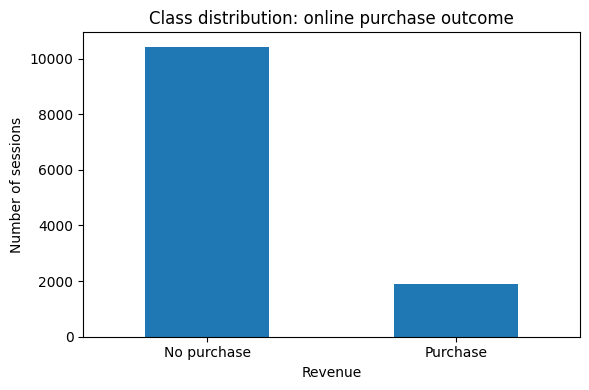

In [ ]:
print('Missing observations per column:')
display(X.isna().sum().to_frame('Missing count'))
print('Exact duplicate feature rows:', X.duplicated().sum())
print('Target distribution:')
display(y.value_counts().rename(index={0:'No purchase',1:'Purchase'}).to_frame('Sessions'))
print('Purchase rate:', f'{y.mean():.2%}')

fig, ax = plt.subplots(figsize=(6, 4))
y.value_counts().sort_index().plot(kind='bar', ax=ax)
ax.set_xticklabels(['No purchase','Purchase'], rotation=0)
ax.set_ylabel('Number of sessions')
ax.set_title('Class distribution: online purchase outcome')
plt.tight_layout()
plt.savefig('01_class_distribution.png', dpi=160)
plt.show()

Selected numerical feature summaries:


,count,mean,std,min,50%,90%,95%,99%,max
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,598.936905,2877.863333,4300.289077,8701.142697,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.003112,0.058197,0.200000,0.200000,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.025156,0.100000,0.200000,0.200000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,18.855502,38.160528,85.498490,361.763742


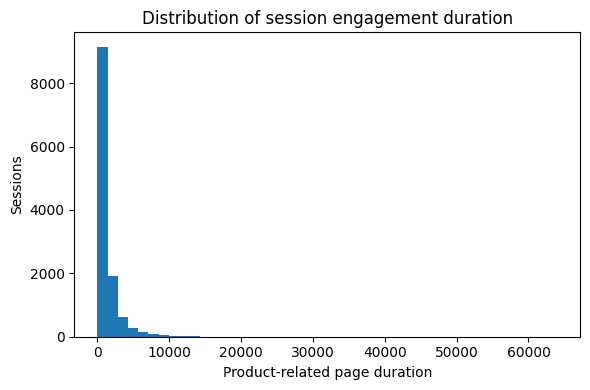

In [ ]:
print('Selected numerical feature summaries:')
feature_subset = [
    'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues'
]
display(X[feature_subset].describe(percentiles=[.50, .90, .95, .99]).T)

fig, ax = plt.subplots(figsize=(6,4))
ax.hist(X['ProductRelated_Duration'].dropna(), bins=45)
ax.set_xlabel('Product-related page duration')
ax.set_ylabel('Sessions')
ax.set_title('Distribution of session engagement duration')
plt.tight_layout()
plt.savefig('02_engagement_distribution.png', dpi=160)
plt.show()

**EDA reflection — complete after running:**

- Missing values: `[INSERT number]` across `[INSERT affected columns]`; justify whether imputation is actually needed.
- Class balance: `[INSERT percent purchases]`. Explain why raw accuracy can be misleading.
- Outliers: Investigate long browsing durations and high PageValues. Do **not** automatically discard valid high-engagement visitors.
- Repeated feature rows: Explain why identical attributes do not necessarily indicate duplicate *sessions*.

*Important:* An outlier is not necessarily an error; clipping or removing it may erase a legitimate business signal.
**Caution:** Repeated feature patterns do not establish duplicate transactions; do not drop them automatically.


### Step 4 — Define feature types and split the data

`OperatingSystems`, `Browser`, `Region`, and `TrafficType` are category **codes**, not continuous quantities. One-hot encode them together with `Month`, `VisitorType`, and `Weekend`. Split into training and testing subsets **before fitting imputation, encoding or scaling** to avoid data leakage.

In [ ]:
categorical_cols = [
    'Month', 'OperatingSystems', 'Browser', 'Region',
    'TrafficType', 'VisitorType', 'Weekend'
]
numerical_cols = [c for c in X.columns if c not in categorical_cols]

# Represent category codes as labels; leave any genuine missing values as NaN.
for col in categorical_cols:
    X[col] = X[col].map(lambda v: str(v) if pd.notna(v) else np.nan)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print('Training rows:', len(X_train), '| Test rows:', len(X_test))
print('Training positive rate:', round(y_train.mean(), 4))
print('Test positive rate:', round(y_test.mean(), 4))

Training rows: 9864 | Test rows: 2466
Training positive rate: 0.1547
Test positive rate: 0.1549


### Step 5 — Build a leakage-safe preprocessing pipeline

- Numeric columns: median imputation (protective if future records contain missing values), followed by standardization to help KNN.
- Categorical columns: most-frequent imputation, followed by one-hot encoding to avoid implying ordinal relationships.
- Gaussian Naive Bayes needs a dense matrix, so request a dense one-hot representation. This dataset is small enough for Colab memory.

**Caution:** Because original UCI data reportedly contain no missing values, you should report **zero missing values observed**, not falsely claim you repaired existing gaps. The imputer is a reproducibility safeguard.

In [ ]:
def make_preprocessor(numeric_columns, categorical_columns):
    numerical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    return ColumnTransformer([
        ('num', numerical_pipeline, numeric_columns),
        ('cat', categorical_pipeline, categorical_columns)
    ])

preprocessing = make_preprocessor(numerical_cols, categorical_cols)
print('Numeric fields:', numerical_cols)
print('Categorical fields:', categorical_cols)

Numeric fields: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
Categorical fields: ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']


### Step 6 — Choose and tune three classification algorithms

**Decision Tree** — useful for nonlinear patterns and interpretable rules; prone to overfitting when deep. We tune depth and minimum leaf size.

**KNN** — captures local similarity; sensitive to feature scale, the number of neighbors, and distance in high dimensions.

**Gaussian Naive Bayes** — fast probabilistic benchmark; conditional-independence and Gaussian-distribution assumptions may not hold for sparse/one-hot shopping variables.

Use 3-fold *stratified* cross-validation **inside the training set only**. Select hyperparameters using F1-score because purchasers are the minority class. The test set remains untouched until final evaluation.

In [ ]:
model_specs = {
    'Decision Tree': (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {'model__max_depth':[5, 10], 'model__min_samples_leaf':[10, 30]}
    ),
    'KNN': (
        KNeighborsClassifier(),
        {'model__n_neighbors':[11, 31]}
    ),
    'Gaussian Naive Bayes': (
        GaussianNB(),
        {'model__var_smoothing':[1e-9, 1e-7]}
    )
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
fitted_models = {}
cv_summary = []

for name, (estimator, grid) in model_specs.items():
    print('Training:', name)
    pipe = Pipeline([
        ('prep', make_preprocessor(numerical_cols, categorical_cols)),
        ('model', estimator)
    ])
    search = GridSearchCV(
        pipe, param_grid=grid, scoring='f1', cv=cv,
        n_jobs=-1, refit=True
    )
    search.fit(X_train, y_train)
    fitted_models[name] = search.best_estimator_
    cv_summary.append({
        'Model':name,
        'Best cross-validated F1':search.best_score_,
        'Best hyperparameters':str(search.best_params_)
    })

cv_table = pd.DataFrame(cv_summary).sort_values('Best cross-validated F1', ascending=False)
display(cv_table)
cv_table.to_csv('cross_validation_summary.csv', index=False)

Training: Decision Tree
Training: KNN
Training: Gaussian Naive Bayes


,Model,Best cross-validated F1,Best hyperparameters
0,Decision Tree,0.627148,"{'model__max_depth': 5, 'model__min_samples_le..."
1,KNN,0.470447,{'model__n_neighbors': 11}
2,Gaussian Naive Bayes,0.309089,{'model__var_smoothing': 1e-07}


### Step 7 — Evaluate on the held-out test set once

Add a **majority-class** baseline. Report accuracy, balanced accuracy, precision, recall, F1, ROC-AUC, and average precision (AP). The AP metric provides a useful summary of precision–recall performance for rare purchases. Selecting the best model based on its test score **after** repeatedly trying different configurations on the same test set invalidates a clean held-out comparison; do not tune after opening test results.

In [ ]:
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
all_models = {'Majority baseline': baseline, **fitted_models}

results = []
for name, model in all_models.items():
    predicted = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]
    results.append({
        'Model':name,
        'Accuracy':accuracy_score(y_test, predicted),
        'Balanced accuracy':balanced_accuracy_score(y_test, predicted),
        'Precision':precision_score(y_test, predicted, zero_division=0),
        'Recall':recall_score(y_test, predicted, zero_division=0),
        'F1':f1_score(y_test, predicted, zero_division=0),
        'ROC-AUC':roc_auc_score(y_test, probability),
        'Average precision':average_precision_score(y_test, probability)
    })

results_table = pd.DataFrame(results).sort_values('F1', ascending=False)
display(results_table.round(3))
results_table.to_csv('test_model_metrics.csv', index=False)

for name, model in fitted_models.items():
    print('\n', name)
    print(classification_report(y_test, model.predict(X_test),
          target_names=['No purchase', 'Purchase'], zero_division=0))

,Model,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC,Average precision
1,Decision Tree,0.899,0.771,0.711,0.586,0.643,0.917,0.686
2,KNN,0.873,0.649,0.693,0.325,0.442,0.816,0.525
3,Gaussian Naive Bayes,0.309,0.571,0.177,0.950,0.299,0.763,0.377
0,Majority baseline,0.845,0.500,0.000,0.000,0.000,0.500,0.155



 Decision Tree
              precision    recall  f1-score   support

 No purchase       0.93      0.96      0.94      2084
    Purchase       0.71      0.59      0.64       382

    accuracy                           0.90      2466
   macro avg       0.82      0.77      0.79      2466
weighted avg       0.89      0.90      0.89      2466


 KNN
              precision    recall  f1-score   support

 No purchase       0.89      0.97      0.93      2084
    Purchase       0.69      0.32      0.44       382

    accuracy                           0.87      2466
   macro avg       0.79      0.65      0.69      2466
weighted avg       0.86      0.87      0.85      2466


 Gaussian Naive Bayes
              precision    recall  f1-score   support

 No purchase       0.95      0.19      0.32      2084
    Purchase       0.18      0.95      0.30       382

    accuracy                           0.31      2466
   macro avg       0.57      0.57      0.31      2466
weighted avg       0.83      

### Step 8 — Visualize and interpret model errors

**Confusion matrix:**
- False positive: predict purchase, but no purchase occurred; campaigns might be mistargeted.
- False negative: predict no purchase, but a purchase occurred; a promising session might be overlooked.

The business cost of these errors depends on what action will be taken with the prediction. Neither error type is automatically more expensive.

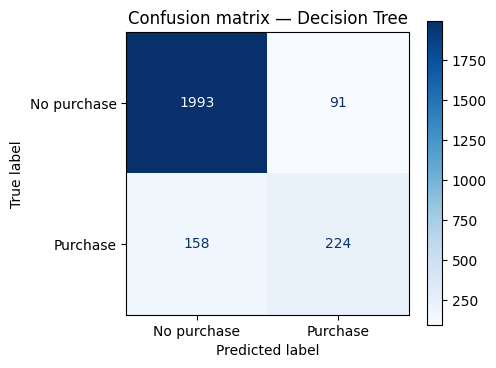

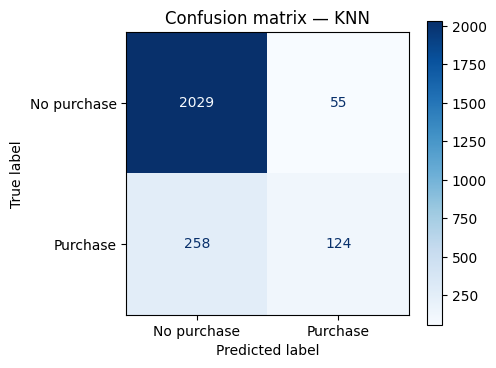

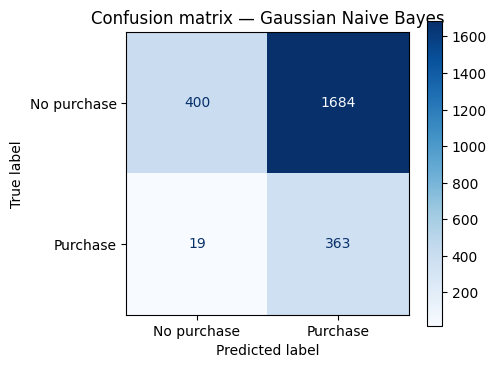

In [ ]:
for name, model in fitted_models.items():
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, ax=ax, cmap='Blues',
        display_labels=['No purchase', 'Purchase'], values_format='d'
    )
    ax.set_title(f'Confusion matrix — {name}')
    plt.tight_layout()
    filename = 'confusion_' + name.lower().replace(' ', '_') + '.png'
    plt.savefig(filename, dpi=160)
    plt.show()

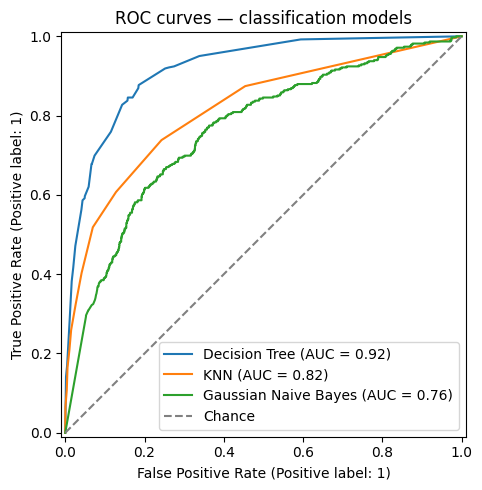

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, model in fitted_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Chance')
ax.set_title('ROC curves — classification models')
ax.legend()
plt.tight_layout()
plt.savefig('03_roc_curves.png', dpi=160)
plt.show()

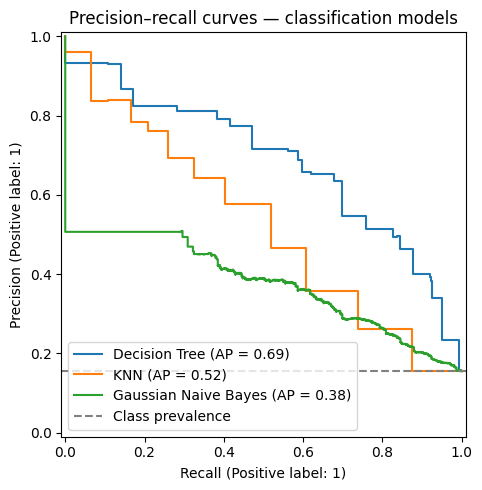

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, model in fitted_models.items():
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, ax=ax, name=name)
ax.axhline(y_test.mean(), color='grey', linestyle='--', label='Class prevalence')
ax.set_title('Precision–recall curves — classification models')
ax.legend()
plt.tight_layout()
plt.savefig('04_precision_recall_curves.png', dpi=160)
plt.show()

### Step 9 — Optional robustness check: remove `PageValues`

`PageValues` reflects a Google Analytics page-level transaction-value metric. Its information availability at the intended prediction time must be verified; a metric derived from outcomes may create a look-ahead problem in a real deployment. Check whether model conclusions change without it. **This test does not prove leakage**; it only assesses sensitivity to a potentially problematic feature.

Do **not** choose the production model solely from repeated test-set ablations. Treat this as an exploratory sensitivity analysis and report it transparently.

In [ ]:
# Use the best training-CV model for an exploratory feature sensitivity check.
cv_best_name = cv_table.iloc[0]['Model']
full_model = fitted_models[cv_best_name]

num_without_page_value = [c for c in numerical_cols if c != 'PageValues']
ablated_model = Pipeline([
    ('prep', make_preprocessor(num_without_page_value, categorical_cols)),
    ('model', clone(full_model.named_steps['model']))
])
ablated_model.fit(X_train.drop(columns='PageValues'), y_train)
ablated_pred = ablated_model.predict(X_test.drop(columns='PageValues'))

print('Chosen by training CV:', cv_best_name)
print('Full-data F1:', round(f1_score(y_test, full_model.predict(X_test)), 3))
print('Without PageValues F1:', round(f1_score(y_test, ablated_pred), 3))

# Record the sensitivity check in the same results bundle as other metrics.
pd.DataFrame([{
    'Model_selected_by_train_CV': cv_best_name,
    'Full_test_F1': f1_score(y_test, full_model.predict(X_test), zero_division=0),
    'Without_PageValues_test_F1': f1_score(y_test, ablated_pred, zero_division=0)
}]).to_csv('pagevalues_ablation.csv', index=False)


Chosen by training CV: Decision Tree
Full-data F1: 0.643
Without PageValues F1: 0.161


### Step 10 — Report your findings in your own academic voice

Replace the bracketed prompts with your **actual outputs**. Do not claim algorithm superiority before inspecting both cross-validation and held-out test performance.

#### 1. Introduction and objective
> Online purchase-intention prediction is relevant to how e-commerce firms allocate marketing resources and tailor shopping experiences. This study evaluates three supervised classification algorithms using the UCI Online Shoppers Purchasing Intention dataset. The main research question is whether the candidate models can identify purchase-ending sessions more effectively than a majority-class baseline.

#### 2. Dataset and EDA
Record source, period (1-year data collection), 12,330 sessions, 17 predictors, binary Revenue outcome, class prevalence, numerical/categorical predictors, missing-value findings, and notable distributions.

#### 3. Preprocessing decisions
Describe the 80/20 stratified split; median and mode imputers **as safeguards if no missing values are observed**; one-hot encoding of coded categories; standardization for KNN; deliberate retention of plausible outliers; train-only fitting inside pipelines.

#### 4. Model selection and evaluation
Justify Decision Tree (interpretable nonlinear rules), KNN (local similarity), and Gaussian NB (fast probabilistic benchmark). State hyperparameter grids and 3-fold stratified cross-validation using training F1. Include the majority-class baseline.

#### 5. Results — fill with measured values
> On the held-out test set, [MODEL] achieved an F1-score of [VALUE], precision of [VALUE], and recall of [VALUE]. The majority-class baseline achieved an F1-score of [VALUE]. The [MODEL] confusion matrix identified [VALUE] false positives and [VALUE] false negatives. These patterns suggest [SPECIFIC INTERPRETATION].

Insert your generated table, confusion matrices and ROC or precision–recall chart.

#### 6. Discussion and limitations
Explain trade-offs in precision, recall and training/prediction costs. Discuss class imbalance, the Gaussian NB assumptions, fixed splits, historical representativeness, lack of external validation, possible temporal leakage from PageValues, and why predictions do **not** establish causal effects.

#### 7. Lessons learned and future work
Reflect on why leakage-safe preprocessing, feature semantics, baselines and minority-class metrics were important. Suggest external/temporal validation, probability calibration, threshold selection based on campaign costs, and fairness or segment monitoring.

#### 8. Conclusion
Summarize what the evidence from your run supports without exaggerating practical deployment readiness.

#### References (APA 7)
Sakar, C., & Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset* [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5F88Q

Sakar, C. O., Polat, S. O., Katircioglu, M., & Kastro, Y. (2019). Real-time prediction of online shoppers’ purchasing intention using multilayer perceptron and LSTM recurrent neural networks. *Neural Computing and Applications, 31*(10), 6893–6908. https://doi.org/10.1007/s00521-018-3523-0

scikit-learn developers. (n.d.). *Common pitfalls and recommended practices*. https://scikit-learn.org/stable/common_pitfalls.html

### Step 11 — Export the deliverables

1. **Google Colab:** `File → Download → Download .ipynb` to submit the executed notebook (ensure results and plots are visible).
2. **Comprehensive report:** Write a separate document using the Step 10 structure and your measured tables/figures; export it to PDF.
3. **Supporting artifacts:** Download `test_model_metrics.csv`, `cross_validation_summary.csv`, and image files from Colab's left **Files** panel. Optionally store a copy in Google Drive.
4. **Submission check:** Notebook runs top-to-bottom, sources credited, no invented scores, hypotheses distinguished from observations, preprocessing fitted within training folds, results interpreted thoughtfully.

**Further experiment if time permits:** Compare the best model with and without scaling using the same training-CV procedure, then discuss whether the result matches the algorithm's theoretical sensitivity to distance. Keep the held-out test set reserved for final reporting.

### Save and download the Colab experiment outputs

This optional cell packages model metrics, plots, and executed notebook-generated tables for your GitHub report. Run it after all model and visualization cells.

In [ ]:
from pathlib import Path
import zipfile
output_files = list(Path('.').glob('*.png')) + list(Path('.').glob('*.csv'))
archive = Path('experiment_outputs.zip')
with zipfile.ZipFile(archive, 'w', compression=zipfile.ZIP_DEFLATED) as bundle:
    for file in output_files:
        bundle.write(file, arcname=file.name)
print(f'Packaged {len(output_files)} output files into {archive}')
try:
    from google.colab import files
    files.download(str(archive))
except ImportError:
    print('Outside Colab: retrieve the zip from your current working folder.')

Packaged 10 output files into experiment_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>